#Monte Carlo Pricing and Risk Engine

This notebook prices European options and measures portfolio risk with Monte Carlo
simulation, and checks every result against a known answer.
Contents: 1. Data  2. Geometric Brownian Motion  3. Option pricing vs Black-Scholes
4. Variance reduction  5. Greeks  6. Portfolio risk (VaR, ES)  7. Backtest  8. Conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf, exp, log, sqrt, pi
import yfinance as yf

In [2]:
rng = np.random.default_rng(42)   #fixed seed for reproducibility

1. Data and historical statistics.

In [3]:
tickers = ["SPY", "AAPL", "MSFT", "JPM"]

In [4]:
raw = yf.download(tickers, start="2019-01-01", end="2026-11-01",
                  auto_adjust=True, progress=False)

In [5]:
prices = raw["Close"].dropna()

In [6]:
prices.shape

(1969, 4)

In [7]:
prices.tail()

Ticker,AAPL,JPM,MSFT,SPY
Date,,,,
2026-10-26,343.648895,334.040009,532.599976,765.369995
2026-10-27,346.836487,335.790009,531.330017,769.659973
2026-10-28,343.568939,339.299988,531.010010,772.309998
2026-10-29,348.645111,343.579987,530.140015,769.359985
2026-10-30,344.368347,337.040009,521.909973,755.719971


In [8]:
log_ret = np.log(prices / prices.shift(1)).dropna()

In [9]:
mu_ann=log_ret.mean()*252
sigma_ann=log_ret.std()*np.sqrt(252)

In [10]:
pd.DataFrame({"mu_ann": mu_ann, "sigma_ann": sigma_ann}).round(3)

,mu_ann,sigma_ann
Ticker,,
AAPL,0.284,0.305
JPM,0.184,0.291
MSFT,0.219,0.291
SPY,0.156,0.192


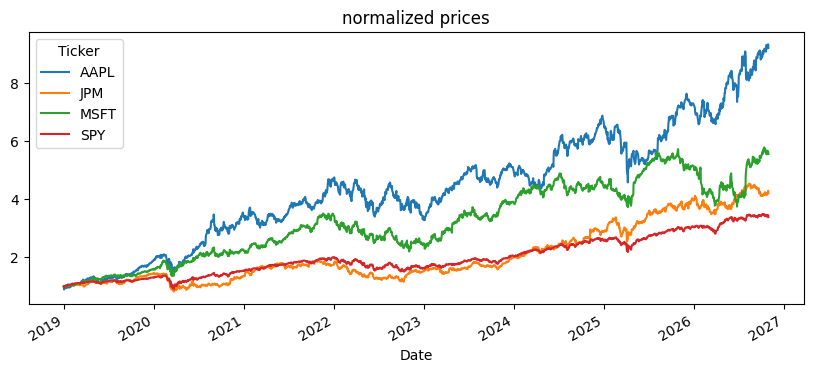

In [11]:
(prices / prices.iloc[0]).plot(figsize=(10, 4), title="normalized prices")
plt.show()

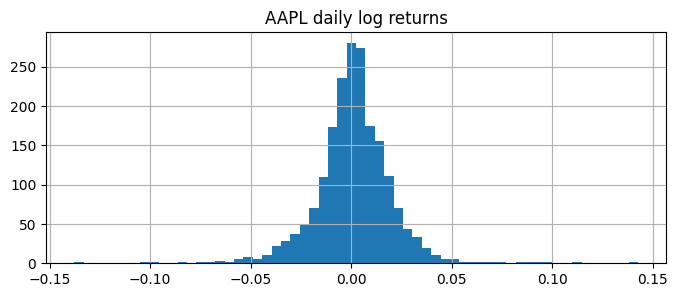

In [12]:
log_ret["AAPL"].hist(bins=60, figsize=(8, 3))
plt.title("AAPL daily log returns")
plt.show()

Data. I downloaded daily adjusted prices for AAPL, MSFT, JPM and SPY from January 2019 to the end of October 2026 (1,969 trading days) and computed daily log returns. Annualised volatility is about 0.19 for SPY and 0.29-0.31 for the three single stocks.
This is expected: a diversified index moves less than individual stocks. The normalised price plot shows that all four assets rose strongly over the period
(AAPL about 9x, SPY about 3.4x) and all fell sharply in early 2020 (COVID) and again in 2025. The high mean return of AAPL (0.28 per year) comes from this specific period;
it is not a forecast. The histogram of AAPL log returns is centred at zero and roughly symmetric, but a few days are extreme (about +/-10-14%), far outside the typical daily move of about 2%. So real returns have fatter tails than a normal distribution. This matters in the
risk section.

2. Geometric Brownian Motion

In [13]:
def simulate_gbm_paths(S0, r, sigma, T, n_steps, n_paths, rng):
    #Simulate GBM price paths under the risk-neutral drift r
    dt = T / n_steps
    z = rng.standard_normal((n_paths, n_steps))
    increments = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    paths = S0 * np.exp(np.cumsum(increments, axis=1))
    return np.hstack([np.full((n_paths, 1), S0), paths])

In [14]:
S0 = float(prices["AAPL"].iloc[-1])

In [15]:
sigma=float(sigma_ann["AAPL"])

In [16]:
r=0.04        #assumed risk-free rate
T=1.0

In [17]:
paths = simulate_gbm_paths(S0, r, sigma, T, 252, 10_000, rng)
ST = paths[:, -1]

In [18]:
print("MC mean of S_T :", ST.mean(), "| theory S0*exp(rT):", S0 * np.exp(r * T))
print("MC std log(S_T/S0):", np.log(ST / S0).std(), "| theory sigma*sqrt(T):", sigma * np.sqrt(T))

MC mean of S_T : 359.43592153995314 | theory S0*exp(rT): 358.42228602324667
MC std log(S_T/S0): 0.30507232606769397 | theory sigma*sqrt(T): 0.30516741489577515


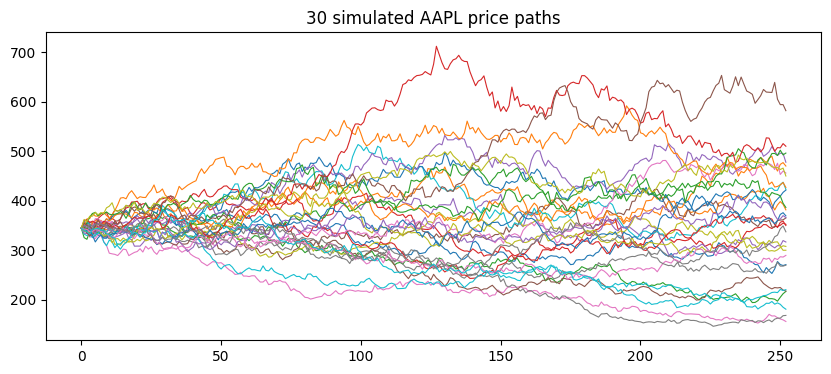

In [19]:
plt.figure(figsize=(10, 4))
plt.plot(paths[:30].T, lw=0.8)
plt.title("30 simulated AAPL price paths")
plt.show()

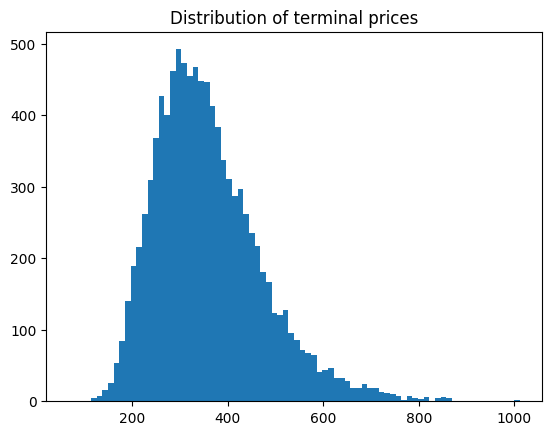

In [20]:
plt.hist(ST, bins=80)
plt.title("Distribution of terminal prices")
plt.show()

Geometric Brownian Motion. At every step the log price changes by a drift plus a random
normal shock. I used the risk-neutral drift r - sigma^2/2 with r = 4% (an assumed
risk-free rate) and sigma = 30.5% (historical volatility of AAPL), starting from the
last price S0 = 344.37 with 252 daily steps (one year). Check: the simulated mean of S_T is 359.4 vs the theoretical S0*exp(rT) = 358.4, and the
standard deviation of log(S_T/S0) is 0.3051 vs the theoretical sigma*sqrt(T) = 0.3052.
So the simulator agrees with the theory.
The path plot shows uncertainty growing with time: after one year the 30 paths range from
about 150 to 700. The histogram of final prices is right-skewed (lognormal): a price
cannot fall below zero but can rise a lot. This is why the mean (359) is above the median (about 342).

3. European option pricing: Monte Carlo vs Black-Scholes

In [21]:
def norm_cdf(x):
    return 0.5 * (1 + erf(x / sqrt(2)))

In [22]:
def bs_price(S0, K, r, sigma, T, kind="call"):
    d1 = (log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt(T))
    d2 = d1 - sigma * sqrt(T)
    if kind == "call":
        return S0 * norm_cdf(d1) - K * exp(-r * T) * norm_cdf(d2)
    return K * exp(-r * T) * norm_cdf(-d2) - S0 * norm_cdf(-d1)

In [23]:
def mc_price(S0, K, r, sigma, T, n_sims, rng, kind="call", antithetic=False):
    #Returns (price, standard error).
    def payoff(ST):
        return np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    drift, vol = (r - 0.5 * sigma**2) * T, sigma * np.sqrt(T)
    if antithetic:
        z = rng.standard_normal(n_sims // 2)
        x = 0.5 * (payoff(S0 * np.exp(drift + vol * z)) + payoff(S0 * np.exp(drift - vol * z)))
    else:
        z = rng.standard_normal(n_sims)
        x = payoff(S0 * np.exp(drift + vol * z))
    x = np.exp(-r * T) * x
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

In [24]:
def mc_price_cv(S0, K, r, sigma, T, n_sims, rng, kind="call"):
    #Control variate: S_T has known mean S0*exp(rT) under the risk-neutral measure.
    z = rng.standard_normal(n_sims)
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z)
    pay = np.maximum(ST - K, 0) if kind == "call" else np.maximum(K - ST, 0)
    x = np.exp(-r * T) * pay
    b = np.cov(x, ST)[0, 1] / ST.var(ddof=1)
    y = x - b * (ST - S0 * np.exp(r * T))
    return y.mean(), y.std(ddof=1) / np.sqrt(n_sims)

In [25]:
K = round(S0 * 1.05, 2)

In [26]:
bs_c = bs_price(S0, K, r, sigma, T, "call")

In [27]:
mc_c, se_c = mc_price(S0, K, r, sigma, T, 1_000_000, rng, "call")

In [28]:
print(f"Black-Scholes call: {bs_c:.4f}")
print(f"Monte Carlo call  : {mc_c:.4f}  (SE {se_c:.4f})")
print(f"95% CI            : [{mc_c - 1.96*se_c:.4f}, {mc_c + 1.96*se_c:.4f}]")
print("Black-Scholes inside CI:", mc_c - 1.96*se_c <= bs_c <= mc_c + 1.96*se_c)

Black-Scholes call: 40.4428
Monte Carlo call  : 40.5114  (SE 0.0728)
95% CI            : [40.3687, 40.6541]
Black-Scholes inside CI: True


In [29]:
Ns = [100, 1_000, 10_000, 100_000, 1_000_000]

In [30]:
res=[mc_price(S0, K, r, sigma, T, n, rng, "call") for n in Ns]

In [31]:
mc_vals = np.array([p for p, _ in res])
ses = np.array([s for _, s in res])

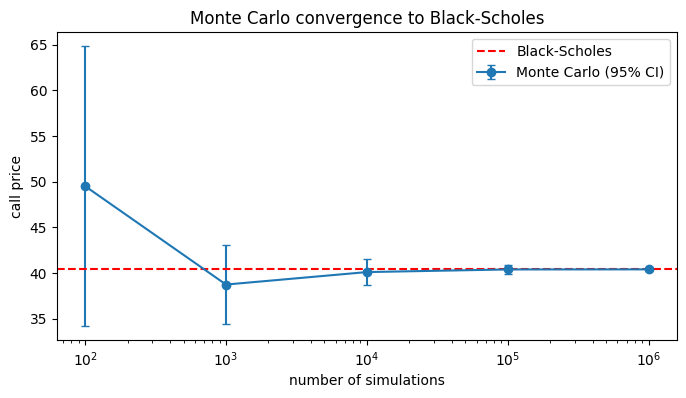

In [32]:
plt.figure(figsize=(8, 4))
plt.errorbar(Ns, mc_vals, yerr=1.96 * ses, fmt="o-", capsize=3, label="Monte Carlo (95% CI)")
plt.axhline(bs_c, color="red", ls="--", label="Black-Scholes")
plt.xscale("log")
plt.xlabel("number of simulations")
plt.ylabel("call price")
plt.title("Monte Carlo convergence to Black-Scholes")
plt.legend()
plt.savefig("convergence.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
bs_p = bs_price(S0, K, r, sigma, T, "put")

In [34]:
mc_p, se_p = mc_price(S0, K, r, sigma, T, 1_000_000, rng, "put")

In [35]:
print(f"Put  BS:{bs_p:.4f}, MC:{mc_p:.4f} (SE {se_p:.4f})")

Put  BS:43.4863, MC:43.4297 (SE 0.0525)


In [36]:
lhs = mc_c - mc_p
rhs = S0 - K * exp(-r * T)

In [37]:
se_diff = sqrt(se_c**2 + se_p**2)

In [38]:
print(f"C - P (MC)={lhs:.4f},S0 - K e^(-rT)={rhs:.4f}, diff={abs(lhs - rhs):.4f} (SE {se_diff:.4f})")

C - P (MC)=-2.9183,S0 - K e^(-rT)=-3.0435, diff=0.1252 (SE 0.0898)


European call with strike K = 361.59 (5% above the current price) and maturity of one
year. Black-Scholes gives 40.44. Monte Carlo with 1,000,000 paths gives 40.51
(standard error 0.07), and the Black-Scholes price lies inside the 95% confidence
interval [40.37, 40.65]. So the Monte Carlo pricer is consistent with the closed-form
formula.
The convergence plot shows that with 100 paths the estimate is far from the true price
and the confidence interval is very wide; the interval shrinks as N grows. The error
decreases like 1/sqrt(N): 100 times more simulations give only 10 times less error.
This is the main cost of Monte Carlo and the reason variance reduction is useful.
Put option: Black-Scholes 43.49, Monte Carlo 43.43 (SE 0.05). Put-call parity:
C - P = -2.92 (MC) vs S0 - K*exp(-rT) = -3.04. The difference of 0.125 is about
1.4 standard errors, which is normal random error.

4. Variance reduction: antithetic variates

In [39]:
reps, n = 2000, 10_000

In [40]:
plain = [mc_price(S0, K, r, sigma, T, n, rng, "call")[0] for _ in range(reps)]
anti = [mc_price(S0, K, r, sigma, T, n, rng, "call", antithetic=True)[0] for _ in range(reps)]
cv = [mc_price_cv(S0, K, r, sigma, T, n, rng, "call")[0] for _ in range(reps)]

In [41]:
sd_p, sd_a, sd_c = np.std(plain, ddof=1), np.std(anti, ddof=1), np.std(cv, ddof=1)

In [42]:
print(f"Plain MC std                       : {sd_p:.5f}")
print(f"Antithetic std                     : {sd_a:.5f}")
print(f"Control variate std                : {sd_c:.5f}")
print(f"Antithetic variance reduction      : {sd_p**2 / sd_a**2:.2f}x")
print(f"Control variate variance reduction : {sd_p**2 / sd_c**2:.2f}x")

Plain MC std                       : 0.72030
Antithetic std                     : 0.60570
Control variate std                : 0.32356
Antithetic variance reduction      : 1.41x
Control variate variance reduction : 4.96x


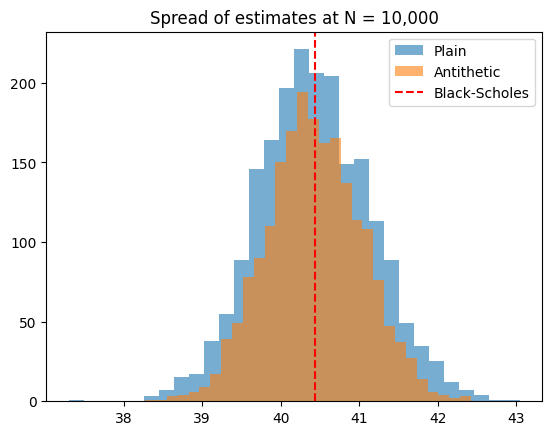

In [43]:
plt.hist(plain, bins=30, alpha=0.6, label="Plain")
plt.hist(anti, bins=30, alpha=0.6, label="Antithetic")
plt.axvline(bs_c, color="red", ls="--", label="Black-Scholes")
plt.legend()
plt.title("Spread of estimates at N = 10,000")
plt.show()

Antithetic variates use each random shock z together with -z. The two payoffs are
negatively correlated, so their average has lower variance than two independent draws.
With the same budget (10,000 payoff evaluations) the standard deviation of the price
estimate went from  0.72030 to 0.60570, a variance reduction of 1.41x.

My first run with 300 repetitions gave only 1.04x. This estimate is noisy, so I repeated
the experiment with 2,000 repetitions.

The control variate uses S_T, whose expected value is known exactly (S0*exp(rT)). The call
payoff is strongly correlated with S_T, so subtracting the correlated part removes most
of the noise(variance reduction  4.96x). A control variate works well for this option,
while antithetic variates give a smaller improvement.

5. Greeks

In [44]:
def price_fixed_z(S0, K, r, sigma, T, z):
    ST = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * z)
    return np.exp(-r * T) * np.maximum(ST - K, 0).mean()

In [45]:
z = rng.standard_normal(1_000_000)
h, dv = 0.01 * S0, 0.001

In [46]:
delta_mc = (price_fixed_z(S0 + h, K, r, sigma, T, z) - price_fixed_z(S0 - h, K, r, sigma, T, z)) / (2 * h)
vega_mc = (price_fixed_z(S0, K, r, sigma + dv, T, z) - price_fixed_z(S0, K, r, sigma - dv, T, z)) / (2 * dv)

In [47]:
d1 = (log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * sqrt(T))
delta_bs = norm_cdf(d1)
vega_bs = S0 * exp(-0.5 * d1**2) / sqrt(2 * pi) * sqrt(T)

In [48]:
print(f"Delta MC: {delta_mc:.4f}, BS: {delta_bs:.4f}")
print(f"Vega MC: {vega_mc:.4f}, BS: {vega_bs:.4f}")

Delta MC: 0.5495, BS: 0.5492
Vega MC: 136.3247, BS: 136.3352


Delta (MC 0.5495, BS 0.5492): if AAPL rises by 1, the call price rises by about 0.55.
Vega (MC 136.3, BS 136.3): if volatility rises by one percentage point (0.01), the call
price rises by about 1.36.
I computed the Greeks by bump-and-reprice: change one input slightly, price again, and
divide the difference by the bump. Both prices use the same random numbers, otherwise the
Monte Carlo noise would be larger than the small price change being measured. The results
match the analytical Greeks to three digits.


6. Portfolio risk: VaR and Expected Shortfall

In [49]:
assets=["AAPL", "MSFT", "JPM"]

In [50]:
V=100_000                         #portfolio value
w=np.array([1/3, 1/3, 1/3])       #equal weights
R=log_ret[assets]                 #log returns used as an approximation of daily returns

In [51]:
R.corr().round(2)

Ticker,AAPL,MSFT,JPM
Ticker,,,
AAPL,1.00,0.64,0.41
MSFT,0.64,1.00,0.39
JPM,0.41,0.39,1.00


In [52]:
def mc_var_es(R_df, w, V, alpha, n, rng):
    mu, cov = R_df.mean().values, R_df.cov().values
    sims = rng.multivariate_normal(mu, cov, size=n)
    loss = -(sims @ w) * V
    var = np.quantile(loss, alpha)
    return var, loss[loss >= var].mean()

In [53]:
def hist_var_es(port_ret, V, alpha):
    loss = -port_ret * V
    var = np.quantile(loss, alpha)
    return var, loss[loss >= var].mean()

In [54]:
port_ret = R.values @ w

In [55]:
rows=[]

In [56]:
for alpha in (0.95, 0.99):
    v_mc, e_mc = mc_var_es(R, w, V, alpha, 500_000, rng)
    v_h, e_h = hist_var_es(port_ret, V, alpha)
    rows.append({"Confidence": alpha, "Method": "Monte Carlo", "VaR": round(v_mc, 0), "ES": round(e_mc, 0)})
    rows.append({"Confidence": alpha, "Method": "Historical", "VaR": round(v_h, 0), "ES": round(e_h, 0)})
pd.DataFrame(rows)

,Confidence,Method,VaR,ES
0,0.95,Monte Carlo,2381.0,3010.0
1,0.95,Historical,2218.0,3517.0
2,0.99,Monte Carlo,3400.0,3915.0
3,0.99,Historical,4100.0,6141.0


Portfolio: 100,000 split equally between AAPL, MSFT and JPM. Correlations are 0.64
(AAPL-MSFT), 0.41 (AAPL-JPM) and 0.39 (MSFT-JPM). JPM, a bank, is the least correlated
with the tech stocks, so it adds the most diversification.

One-day risk figures (portfolio of 100,000):
- 95%: VaR 2,381 (MC) vs 2,218 (historical); ES 3,010 vs 3,517
- 99%: VaR 3,400 (MC) vs 4,100 (historical); ES 3,915 vs 6,141
Reading: with 99% probability the portfolio does not lose more than about 3,400-4,100 in
one day. Expected Shortfall is the average loss on the worst 1% of days.
The methods are close at 95% but differ in the tail. For a normal distribution the ratio
ES/VaR at 99% is about 1.15, and the Monte Carlo result matches it (3,915/3,400 = 1.15).
The historical ratio is 1.50, so the worst days are much worse than the normal model
assumes. This is the fat-tail effect seen in the AAPL histogram. A normal-based Monte
Carlo VaR therefore underestimates tail risk.

7. Backtest

In [57]:
from scipy.stats import chi2

In [63]:
def kupiec_pvalue(n_exc, n_obs, p):
    #Proportion-of-failures test: H0=true exceedance rate equals p.
    pi = n_exc / n_obs
    ll0 = (n_obs - n_exc) * np.log(1 - p) + n_exc * np.log(p)
    ll1 = ((n_obs - n_exc) * np.log(1 - pi) + n_exc * np.log(pi)) if 0 < n_exc < n_obs else 0.0
    return 1 - chi2.cdf(-2 * (ll0 - ll1), 1)

In [64]:
split= int(len(R) * 0.7)

In [65]:
R_train, R_test = R.iloc[:split], R.iloc[split:]

In [66]:
test_loss=-(R_test.values @ w) * V

In [70]:
print("Train:", R_train.index[0].date(), "to", R_train.index[-1].date(), f"({len(R_train)} days)")
print("Test :", R_test.index[0].date(), "to", R_test.index[-1].date(), f"({len(R_test)} days)")

Train: 2019-01-03 to 2024-06-24 (1377 days)
Test : 2024-06-25 to 2026-10-30 (591 days)


In [68]:
n_obs = len(test_loss)

In [69]:
for alpha in (0.95, 0.99):
    v_mc, _ = mc_var_es(R_train, w, V, alpha, 500_000, rng)
    v_h, _ = hist_var_es(R_train.values @ w, V, alpha)
    for name, v in [("Monte Carlo", v_mc), ("Historical", v_h)]:
        k = int((test_loss > v).sum())
        print(f"{alpha:.0%} {name:11s}: {k}/{n_obs} exceedances "
              f"({k / n_obs:.1%}, expected {1 - alpha:.0%}), "
              f"Kupiec p-value={kupiec_pvalue(k, n_obs, 1 - alpha):.3f}")

95% Monte Carlo: 13/591 exceedances (2.2%, expected 5%), Kupiec p-value=0.000
95% Historical : 20/591 exceedances (3.4%, expected 5%), Kupiec p-value=0.056
99% Monte Carlo: 3/591 exceedances (0.5%, expected 1%), Kupiec p-value=0.184
99% Historical : 2/591 exceedances (0.3%, expected 1%), Kupiec p-value=0.061


Backtest. VaR was estimated on the first 70% of the data (until about mid-2024) and tested
on the remaining 591 days. A correct 95% VaR should be exceeded on about 5% of days and a
99% VaR on about 1%.
Observed exceedances: 95%: 2.2% (MC) and 3.4% (historical); 99%: 0.5% and 0.3%.
All are below the expected rate, so both models were conservative in the test period.

Likely reasons:training period includes the 2020 crash, which inflates the VaR,
and the test period was calmer. At the 99% level, neither model is rejected ($p = 0.184$ for MC and $p = 0.061$ for historical), though with only 2–3 exceedances in 591 days, the test has low statistical power for a strong conclusion.

At the 95% level, the test rejects the Monte Carlo model ($p=0.000<0.05$) because it is significantly too conservative (2.2% vs. 5% expected), whereas the historical model is borderline accepted ($p=0.056>0.05$).
A conservative VaR is safer than an aggressive one, but it ties up more capital than
needed. A well-calibrated model should be close to the expected rate.

8. Conclusion

I built Monte Carlo pricing and risk tools with NumPy and validated them
against closed-form results: option prices against Black-Scholes, Greeks against
analytical Greeks, and put-call parity. The convergence plot confirms the 1/sqrt(N) error
rate. In this setup, antithetic sampling reduced the variance by a factor of about 1.41x, and the control variate by about 4.96x. The call payoff is strongly correlated with S_T, whose mean is known exactly, so the control variate is much more effective here than antithetic pairing. The risk section shows that
a normal model underestimates tail losses compared with historical data.
Limitations.
- GBM assumes constant volatility and normal returns; real markets have volatility
  clustering and fat tails.
- Volatility is historical, not implied from market option prices.
- The risk-free rate is a fixed assumption (4%).
- Log returns are used as an approximation of simple returns in the portfolio.
- The backtest uses one static split, not a rolling window, and the test sample is short.
Possible extensions: stochastic volatility (Heston), implied volatility from market
prices, path-dependent options (Asian, barrier), rolling-window backtest.